# 01 · Exploratory Data Analysis

Goal: understand the EventFlow data well enough to justify **how we build training examples, which
features to engineer, which models to use, and how to validate**. Every section ends with **Notes**
that interpret the results for our modelling decisions; Section 9 summarises them as findings → decisions.

**Test labels are never loaded in this notebook.** For the test set we only look at the prefixes.

Common yardstick used throughout: **mutual information (MI) with the next event**, in nats.
It measures how much knowing a variable reduces uncertainty about the next event
(0 = useless; the upper bound is the entropy of the next event, 2.24 nats). It is computed
in-sample, so treat small differences as noise.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from eventflow.config import FIGURES_DIR, RANDOM_STATE
from eventflow.data import load_train, load_test, column_groups

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50, "display.width", 160, "display.precision", 4)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIGURES_DIR / f"eda_{name}.png", dpi=150, bbox_inches="tight")

train = load_train()
test = load_test()
cols = column_groups(train)
SENSORS = [c for c in cols["numeric"] if c != "severity"]
print("train", train.shape, "| test", test.shape)
print({k: len(v) for k, v in cols.items()}, "| sensors:", len(SENSORS))

train (1203963, 26) | test (138828, 26)
{'ids': 3, 'categorical': 6, 'numeric': 17} | sensors: 16


In [2]:
# Helpers shared by the sections below
CLASSES = sorted(train["event_type"].unique())
K = len(CLASSES)
SHORT = {c: c.replace("_WARNING", "_W").replace("COMPONENT_", "COMP_").replace("MAINTENANCE_", "MAINT_")
         for c in CLASSES}

def add_basics(df):
    df = df.copy()
    df["ev"] = pd.Categorical(df["event_type"], categories=CLASSES).codes.astype(np.int16)
    g = df.groupby("sequence_id", sort=False)
    df["pos"] = g.cumcount()
    df["dt"] = g["timestamp"].diff()
    return df

train = add_basics(train)
test = add_basics(test)

# Supervised view of train: each row's target is the NEXT event in the same sequence
train["y"] = train.groupby("sequence_id", sort=False)["ev"].shift(-1)
sup = train[train["y"].notna()].copy()
sup["y"] = sup["y"].astype(np.int16)
print(f"supervised rows: {len(sup):,}")

def entropy(p):
    p = np.asarray(p, float); p = p[p > 0]
    return float(-(p * np.log(p)).sum())

def mutual_info(x, y=None):
    """MI (nats) between a discrete/binned x and the next event. NaN in x = its own bin."""
    y = sup["y"] if y is None else y
    x = pd.Series(np.asarray(x)).astype("object").fillna("NaN").to_numpy()
    ct = pd.crosstab(x, np.asarray(y)).to_numpy(float)
    p = ct / ct.sum()
    px, py = p.sum(1, keepdims=True), p.sum(0, keepdims=True)
    nz = p > 0
    return float((p[nz] * np.log(p[nz] / (px @ py)[nz])).sum())

def qbin(s, q=10):
    """Quantile-bin a numeric series (NaN kept as NaN)."""
    return pd.qcut(s, q=q, labels=False, duplicates="drop")

H_next = entropy(np.bincount(sup["y"], minlength=K) / len(sup))
print(f"Entropy of next event: {H_next:.3f} nats (uniform over {K} = {np.log(K):.3f})")

# Test-like rows: targets at the positions the test set asks about (prefix length 90-220, see Section 3)
TL = sup.index[(sup["pos"] + 1).between(90, 220)]
print(f"test-like rows (prefix length 90-220): {len(TL):,} from {sup.loc[TL, 'sequence_id'].nunique():,} sequences")

def cond_mi_on(x, rows):
    """I(x; next | current event) on the given rows only. x must be indexed like sup."""
    tot = 0.0
    for _, idx in rows.groupby("ev").groups.items():
        tot += len(idx) / len(rows) * mutual_info(np.asarray(x.loc[idx]), rows.loc[idx, "y"])
    return tot

supervised rows: 1,197,463
Entropy of next event: 2.239 nats (uniform over 14 = 2.639)
test-like rows (prefix length 90-220): 596,953 from 6,500 sequences


## 1. Overview & sanity checks
Column groups, types, and whether the data is internally consistent: rows ordered, `event_index`
gap-free, time never going backwards, no duplicates.

In [3]:
print("Column groups:")
for k, v in cols.items():
    print(f"  {k:12s} {v}")
display(train[cols["ids"] + cols["categorical"] + ["severity"] + SENSORS[:4]].head())

Column groups:
  ids          ['sequence_id', 'event_index', 'timestamp']
  categorical  ['event_type', 'subsystem', 'shift_code', 'operator_group', 'device_family', 'firmware_channel']
  numeric      ['severity', 'load_reading', 'temperature_reading', 'temp_probe_b', 'vibration_reading', 'vibration_probe_b', 'pressure_reading', 'power_draw', 'coolant_flow', 'control_signal', 'ambient_index', 'efficiency_estimate', 'acoustic_level', 'telemetry_ch_1', 'telemetry_ch_3', 'telemetry_ch_4', 'telemetry_ch_2']


,sequence_id,event_index,timestamp,event_type,subsystem,shift_code,operator_group,device_family,firmware_channel,severity,load_reading,temperature_reading,temp_probe_b,vibration_reading
0,TR00000,0,0.7944,COOLING_FAULT,Cooling,0,G4,F3,FW3,2,0.5728,0.1147,0.3501,0.1312
1,TR00000,1,3.7847,LOAD_INCREASE,Power,0,G4,F3,FW3,0,0.5897,-0.2662,0.2922,0.4237
2,TR00000,2,6.0062,COOLING_FAULT,Cooling,0,G4,F3,FW3,2,0.6704,0.4186,0.4039,0.4747
3,TR00000,3,7.1191,SENSOR_RESET,Control,0,G4,F3,FW3,0,0.5693,0.3126,0.5897,0.4486
4,TR00000,4,7.6878,MAINTENANCE_CHECK,General,0,G4,F3,FW3,0,0.5070,0.3634,0.7720,0.4465


In [4]:
def sanity(df, name):
    g = df.groupby("sequence_id", sort=False)
    return pd.Series({
        "sequences": df["sequence_id"].nunique(),
        "rows": len(df),
        "event_index == 0..n-1": bool((df["event_index"] == df["pos"]).all()),
        "timestamps non-decreasing": bool((df["dt"].dropna() >= 0).all()),
        "zero time gaps (frac)": float((df["dt"] == 0).mean()),
        "duplicate rows": int(df.duplicated(subset=["sequence_id", "event_index"]).sum()),
        "first timestamp (median)": float(g["timestamp"].first().median()),
        "train/test sequence overlap": len(set(df["sequence_id"]) & set(train["sequence_id"])) if name == "test" else None,
    }, name=name)

display(pd.concat([sanity(train, "train"), sanity(test, "test")], axis=1))

,train,test
sequences,6500,900
rows,1203963,138828
event_index == 0..n-1,True,True
timestamps non-decreasing,True,True
zero time gaps (frac),0.0,0.0
duplicate rows,0,0
first timestamp (median),1.337,1.3288
train/test sequence overlap,None,0


> **Notes**
>
> - **Consistency:** indices are gap-free, time is strictly increasing (no zero gaps) and there are no duplicate rows, so no cleaning is needed.
> - **Unseen systems:** test sequences share no `sequence_id` with train, so validation must be grouped by `sequence_id`.
> - **Decision:** identifier columns (`sequence_id`, `event_index`, `timestamp`) are used only for grouping and for deriving features such as position and time gaps, never as raw inputs.

## 2. Target classes
The 14 next-event classes, how imbalanced they are, and what the class prior alone scores.
For the test set we look at the **last observed event** of each prefix (not the label).

,train: next event,test: last observed event,train: all events
RECOVERY,0.2665,0.3044,0.2651
MAINTENANCE_CHECK,0.1371,0.1322,0.1370
TEMP_WARNING,0.1254,0.1111,0.1251
VIBRATION_WARNING,0.1084,0.1100,0.1082
COOLING_FAULT,0.1022,0.0867,0.1018
COOLING_ACTIVATED,0.0554,0.0533,0.0553
COMPONENT_REPLACED,0.0505,0.0456,0.0503
EMERGENCY_STOP,0.0424,0.0356,0.0423
LOAD_INCREASE,0.0361,0.0389,0.0367
LOAD_DECREASE,0.0227,0.0244,0.0231


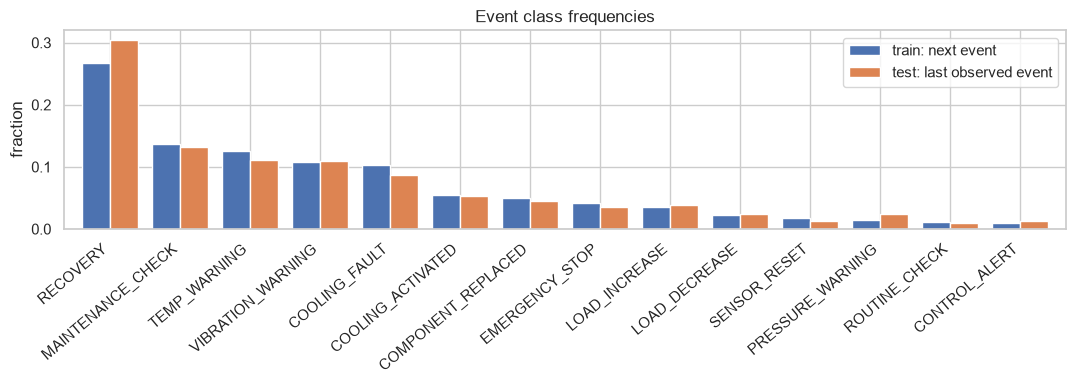

Log loss of predicting the class prior for everyone: 2.239  (uniform: 2.639)
Most/least frequent ratio: 28.5x


In [5]:
freq = pd.DataFrame({
    "train: next event": sup["y"].map(dict(enumerate(CLASSES))).value_counts(normalize=True),
    "test: last observed event": test.groupby("sequence_id")["event_type"].last().value_counts(normalize=True),
    "train: all events": train["event_type"].value_counts(normalize=True),
}).reindex(CLASSES).sort_values("train: next event", ascending=False)
display(freq)

ax = freq[["train: next event", "test: last observed event"]].plot.bar(figsize=(11, 4), width=0.8)
ax.set_ylabel("fraction"); ax.set_title("Event class frequencies")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); savefig("class_freq"); plt.show()

prior = freq["train: next event"].to_numpy()
print(f"Log loss of predicting the class prior for everyone: {entropy(prior):.3f}  (uniform: {np.log(K):.3f})")
print(f"Most/least frequent ratio: {prior.max() / prior.min():.1f}x")

> **Notes**
>
> - **Imbalance:** moderate, 28.5× between RECOVERY (26.7%) and CONTROL_ALERT (0.9%); even the rarest class has about 11k training targets.
> - **Reference scores:** predicting the class prior scores 2.239 (uniform: 2.639). This is a **ceiling**: any model scoring worse is broken. The brief's transition-table baseline (1.81) shows that the current event alone is already worth about 0.43 nats.
> - **Test prefixes:** their last-event mix differs slightly from all training targets (RECOVERY 30.4% vs. 26.7%), but matches training events at the same positions (χ² p = 0.36, Section 3). The difference comes from the warm-up phase, not from a different population.
> - **Decision:** log loss punishes overconfidence, so models must never assign near-zero probability to rare classes. We don't re-weight or oversample, because that would distort calibration.

## 3. Sequence lengths & position in the sequence
Test prefixes are cut from longer histories. We need to know how prefix lengths compare with
training lengths, and whether the event mix **drifts with position**. If it does, position or
time-since-start is informative, and training examples should be cut at test-like positions.

,count,mean,std,min,25%,50%,75%,max
train full length,6500.0,185.2251,38.1014,120.0,152.0,185.0,219.0,250.0
test prefix length,900.0,154.2533,37.5730,90.0,120.0,155.0,188.0,220.0


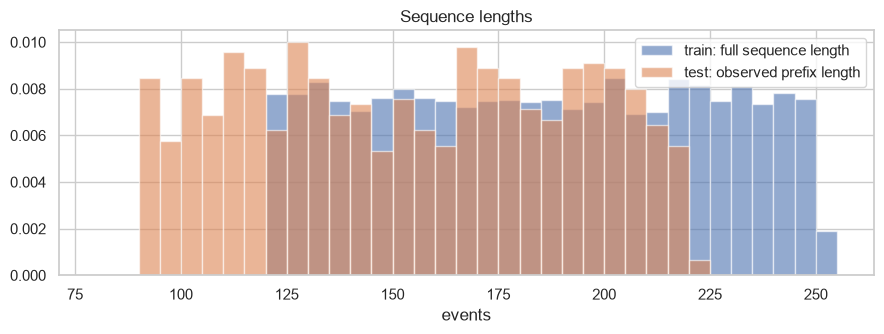

In [6]:
len_train = train.groupby("sequence_id").size()
len_test = test.groupby("sequence_id").size()
display(pd.DataFrame({"train full length": len_train.describe(), "test prefix length": len_test.describe()}).T)

fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.arange(80, 260, 5)
ax.hist(len_train, bins=bins, alpha=.6, label="train: full sequence length", density=True)
ax.hist(len_test, bins=bins, alpha=.6, label="test: observed prefix length", density=True)
ax.set_xlabel("events"); ax.legend(); ax.set_title("Sequence lengths")
plt.tight_layout(); savefig("lengths"); plt.show()

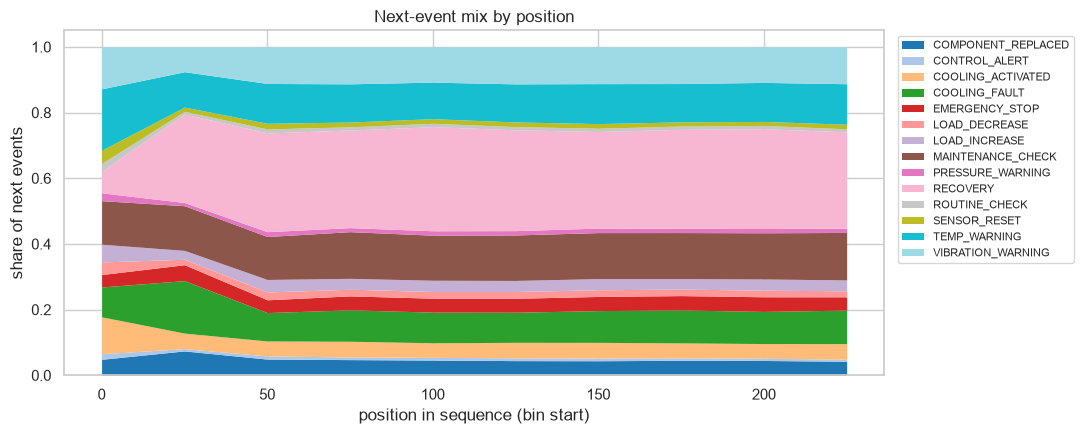

MI(position bin; next) = 0.0320 nats
MI(timestamp decile; next) = 0.0362 nats


In [7]:
# Event mix by position (bins of 25 events)
pos_bin = (sup["pos"] // 25) * 25
mix = pd.crosstab(pos_bin, sup["y"].map(dict(enumerate(CLASSES))), normalize="index")
ax = mix.plot.area(figsize=(11, 4.5), cmap="tab20", linewidth=0)
ax.set_xlabel("position in sequence (bin start)"); ax.set_ylabel("share of next events")
ax.set_title("Next-event mix by position"); ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); savefig("mix_by_position"); plt.show()

print(f"MI(position bin; next) = {mutual_info(pos_bin):.4f} nats")
print(f"MI(timestamp decile; next) = {mutual_info(qbin(sup['timestamp'])):.4f} nats")

**Is the end of a sequence special?** Test prefix lengths (90–220) look like training lengths (120–250) shifted by 30, which suggests each test prefix is a full sequence with its last ~30 events removed. If events near the end of a sequence behaved differently, training examples would have to be cut at that same distance from the end. We check:
1. which offset best matches the two length distributions (KS test; high p = no evidence they differ),
2. whether the next-event mix changes with the distance to the end (KL against the mix at test-like positions, compared with a noise level),
3. whether the test prefixes' last observed events match training events at the same positions (chi-square test),
4. whether position or distance-to-end still carry information **inside** the test range.

In [8]:
from scipy import stats

# (1) Which offset makes (train length - offset) look like the test prefix lengths?
ks_p = pd.Series({off: stats.ks_2samp(len_test, len_train - off).pvalue for off in [20, 25, 30, 35, 40]})
display(ks_p.rename_axis("offset").to_frame("KS p-value").T.round(4))

# (2) Next-event mix by distance to the end of the sequence, compared with the mix at test-like positions
tgt_idx = sup["pos"] + 1                                     # index of the target event
to_end = sup["sequence_id"].map(len_train) - 1 - tgt_idx     # events still to come after the target
test_like = tgt_idx.between(90, 220)                         # target index inside the test range
ref = np.bincount(sup.loc[test_like, "y"], minlength=K) / test_like.sum()

def kl_to_ref(y):
    p = np.bincount(y, minlength=K) / len(y)
    nz = p > 0
    return float((p[nz] * np.log(p[nz] / ref[nz])).sum())

end_mix = pd.DataFrame([
    {"to_end": d, "n": int((to_end == d).sum()),
     "KL vs test-like mix": kl_to_ref(sup.loc[to_end == d, "y"]),
     "RECOVERY share": float((sup.loc[to_end == d, "y"] == CLASSES.index("RECOVERY")).mean())}
    for d in [0, 1, 2, 5, 10, 20, 29, 40, 60]
]).set_index("to_end")
display(end_mix.round(4))

# Noise level: KL of random samples of the same size (one per sequence) drawn from the test-like rows
rng3 = np.random.default_rng(RANDOM_STATE)
y_test_like = sup.loc[test_like, "y"].to_numpy()
noise_kl = [kl_to_ref(rng3.choice(y_test_like, size=len(len_train), replace=False)) for _ in range(20)]
print(f"KL noise level (random {len(len_train)}-row samples): mean {np.mean(noise_kl):.4f}, max {np.max(noise_kl):.4f}")

# (3) Test prefixes' last observed event vs. training events at test-like positions (chi-square goodness of fit)
obs = np.bincount(test.groupby("sequence_id")["ev"].last(), minlength=K)
p_train = np.bincount(train.loc[train["pos"].between(89, 219), "ev"], minlength=K) / train["pos"].between(89, 219).sum()
print(f"chi2: test last observed vs. train positions 89-219: p = {stats.chisquare(obs, p_train * obs.sum()).pvalue:.3f}")

# (4) Inside the test range, do position or distance-to-end still carry information?
y_tl = sup.loc[test_like, "y"]
print(f"MI(position bin; next)        = {mutual_info(tgt_idx[test_like] // 25, y_tl):.4f} nats")
print(f"MI(distance-to-end bin; next) = {mutual_info(np.minimum(to_end[test_like] // 10, 10), y_tl):.4f} nats")
print(f"MI(shuffled, noise)           = {mutual_info(rng3.permutation(tgt_idx[test_like].to_numpy() // 25), y_tl):.4f} nats")

offset,20,25,30,35,40
KS p-value,0.0,0.0058,0.7818,0.0333,0.0


,n,KL vs test-like mix,RECOVERY share
to_end,,,
0,6500,0.0016,0.3225
1,6500,0.0008,0.3112
2,6500,0.0007,0.3186
5,6500,0.0008,0.3115
10,6500,0.0003,0.2998
20,6500,0.0005,0.3028
29,6500,0.0010,0.3100
40,6500,0.0005,0.3043
60,6500,0.0007,0.3088


KL noise level (random 6500-row samples): mean 0.0010, max 0.0017
chi2: test last observed vs. train positions 89-219: p = 0.361
MI(position bin; next)        = 0.0003 nats
MI(distance-to-end bin; next) = 0.0002 nats
MI(shuffled, noise)           = 0.0001 nats


> **Notes**
>
> - **Lengths:** training histories are uniform over 120–250 events and test prefixes over 90–220 (the same width, shifted by 30).
> - **How the test prefixes were made:** almost certainly full sequences with their last 30 events removed. Shifting the training lengths by exactly 30 reproduces the test lengths (KS p = 0.78, same min/max of 90/220), while offsets of 25 or 35 are rejected (p = 0.006 and 0.03).
> - **Warm-up phase:** the next-event mix changes only during the first ~50 events (RECOVERY about 7% instead of ~31%) and is flat afterwards. Position and time MI (about 0.03) come almost entirely from this phase.
> - **The end of a sequence is not special:** at every distance from the end (0–60 events) the next-event mix is within sampling noise of the test-like mix (KL 0.0003–0.0016 vs. a noise level of up to 0.0017); the test prefixes' last observed events match training events at the same positions (χ² p = 0.36); and inside the test range neither position nor distance-to-end carries information (MI 0.0003 / 0.0002 vs. 0.0001 noise).
> - **Decision:** training targets are cut at any prefix length in 90–220, not only 30 events before the end. That gives 596,953 test-like examples instead of 6,500. Earlier events stay available as **history** but are not used as targets. Position is a low-priority feature.

## 4. Sequential dependence: how much does the history tell us?

**4a. n-gram models on a held-out split.** Predict the next event from the last *k* events
(add-α smoothing, backing off to the class prior for unseen contexts). Fitted on 80% of sequences
and scored on the other 20% with **log loss**. The smoothing strength α is picked on that same 20%, so the scores are slightly optimistic.
This is an exploratory measurement of how much
information the recent history carries, not our official validation setup (that's step 2).

,val log loss,alpha,possible contexts
k (events of history),,,
0,2.2379,0.05,1
1,1.8330,0.05,15
2,1.7276,1.00,225
3,1.6970,1.00,3375
4,1.7260,1.00,50625
5,1.7899,1.00,759375
6,1.8719,1.00,11390625
7,1.9473,0.20,170859375


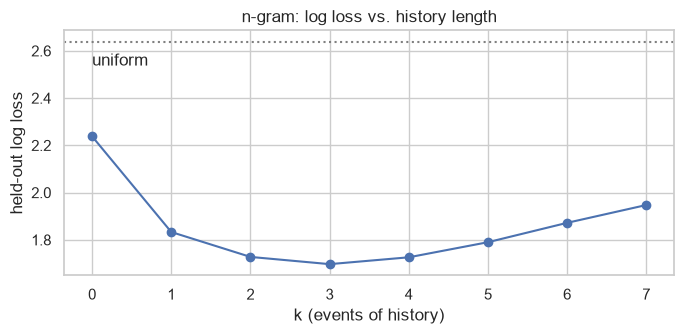

In [9]:
START = K  # code used for "before the sequence started"
for j in range(1, 8):
    sup[f"lag{j}"] = train.groupby("sequence_id", sort=False)["ev"].shift(j).loc[sup.index].fillna(START).astype(np.int16)
sup["lag0"] = sup["ev"]

rng = np.random.default_rng(RANDOM_STATE)
seq_ids = sup["sequence_id"].unique()
val_ids = set(rng.choice(seq_ids, size=len(seq_ids) // 5, replace=False))
is_val = sup["sequence_id"].isin(val_ids).to_numpy()

def ngram_logloss(k, alpha):
    key = np.zeros(len(sup), dtype=np.int64)
    for j in range(k):
        key = key * (K + 1) + sup[f"lag{j}"].to_numpy()
    y = sup["y"].to_numpy()
    uniq, key_c = np.unique(key, return_inverse=True)
    counts = np.zeros((len(uniq), K))
    np.add.at(counts, (key_c[~is_val], y[~is_val]), 1)
    prior = np.bincount(y[~is_val], minlength=K) / (~is_val).sum()
    n = counts.sum(1, keepdims=True)
    probs = (counts + alpha * K * prior) / (n + alpha * K)   # smoothing towards the prior
    p = probs[key_c[is_val], y[is_val]]
    return float(-np.log(p).mean())

rows = []
for k in range(0, 8):
    best = min((ngram_logloss(k, a), a) for a in [0.05, 0.2, 1, 5])
    rows.append({"k (events of history)": k, "val log loss": best[0], "alpha": best[1],
                 "possible contexts": (K + 1) ** k})
ngram = pd.DataFrame(rows).set_index("k (events of history)")
display(ngram)

ax = ngram["val log loss"].plot(marker="o", figsize=(7, 3.5))
ax.axhline(np.log(K), ls=":", c="grey"); ax.text(0, np.log(K) - .05, "uniform", va="top")
ax.set_ylabel("held-out log loss"); ax.set_title("n-gram: log loss vs. history length")
plt.tight_layout(); savefig("ngram_logloss"); plt.show()

**4b. Transition matrix** P(next event | current event). Rows sum to 1.

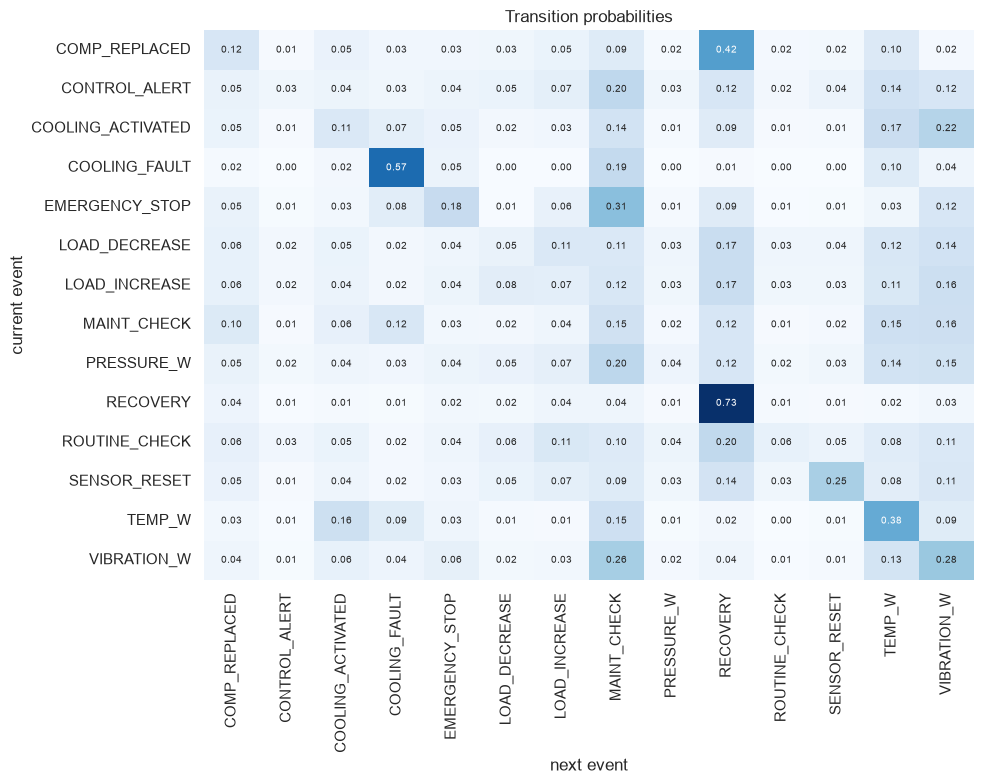

In [10]:
trans = pd.crosstab(sup["event_type"], sup["y"].map(dict(enumerate(CLASSES))), normalize="index")
trans = trans.rename(index=SHORT, columns=SHORT)
plt.figure(figsize=(10, 8))
sns.heatmap(trans, annot=True, fmt=".2f", cmap="Blues", cbar=False, annot_kws={"size": 7})
plt.xlabel("next event"); plt.ylabel("current event"); plt.title("Transition probabilities")
plt.tight_layout(); savefig("transition_matrix"); plt.show()

**4c. How far back does the dependence reach?** MI between the event *k* steps back and the next
event, for k = 0…60. If the curve stays above zero for a long way, short n-grams cannot capture
it and long-context models (RNN/Transformer) or long-window count features are needed.

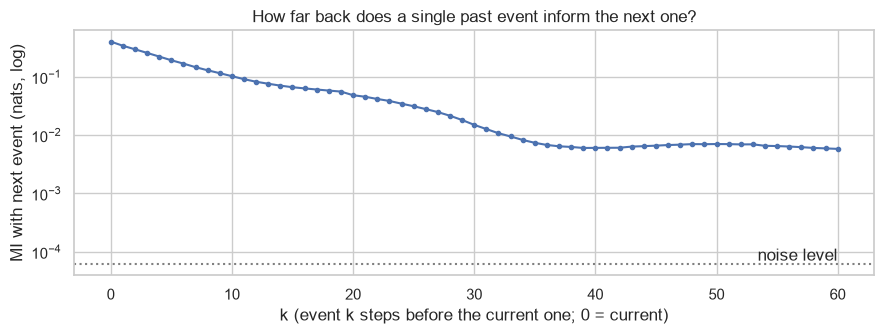

0     0.4030
1     0.3421
2     0.2973
3     0.2579
5     0.1928
10    0.1029
20    0.0485
40    0.0061
60    0.0058


In [11]:
ev = train["ev"].to_numpy(); pos = train["pos"].to_numpy()
y_full = train["y"].to_numpy()
lag_mi = {}
for k in range(0, 61):
    idx = np.where(~np.isnan(y_full) & (pos >= k))[0]
    lag_mi[k] = mutual_info(ev[idx - k], y_full[idx].astype(int))
lag_mi = pd.Series(lag_mi)

# Reference: MI expected purely from finite-sample noise (shuffle x)
noise = mutual_info(rng.permutation(sup["ev"].to_numpy()))

ax = lag_mi.plot(marker=".", figsize=(9, 3.5), logy=True)
ax.axhline(noise, ls=":", c="grey"); ax.text(60, noise, "noise level", ha="right", va="bottom")
ax.set_xlabel("k (event k steps before the current one; 0 = current)"); ax.set_ylabel("MI with next event (nats, log)")
ax.set_title("How far back does a single past event inform the next one?")
plt.tight_layout(); savefig("lag_mi"); plt.show()
print(lag_mi.iloc[[0, 1, 2, 3, 5, 10, 20, 40, 60]].round(4).to_string())

**4d. Aggregate history.** Does the *composition* of the recent window carry information beyond
the last few events? Example: count of each event type in the last 30 events, then MI of each count
with the next event.

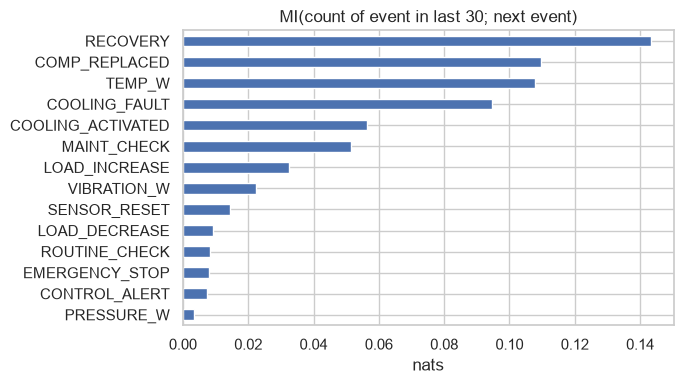

In [12]:
W = 30
onehot = np.eye(K, dtype=np.int32)[train["ev"].to_numpy()]
cs = np.cumsum(onehot, axis=0)
cs_shift = np.vstack([np.zeros((W, K), np.int32), cs[:-W]])
window_counts = cs - cs_shift
# For rows with pos < W the window would cross sequence boundaries; use the in-sequence cumulative count instead
first_idx = train.groupby("sequence_id", sort=False).cumcount().to_numpy() == 0
start_rows = np.where(first_idx)[0]
seq_base = np.repeat(np.vstack([np.zeros((1, K), np.int32), cs[start_rows[1:] - 1]]),
                     np.diff(np.append(start_rows, len(train))), axis=0)
window_counts = np.where((pos < W)[:, None], cs - seq_base, window_counts)
wc = pd.DataFrame(window_counts, columns=CLASSES, index=train.index).loc[sup.index]

count_mi = pd.Series({c: mutual_info(wc[c].clip(upper=10)) for c in CLASSES}).sort_values(ascending=False)
count_mi.rename(SHORT).plot.barh(figsize=(7, 4), title=f"MI(count of event in last {W}; next event)")
plt.xlabel("nats"); plt.gca().invert_yaxis(); plt.tight_layout(); savefig("window_count_mi"); plt.show()

In [13]:
# Do window counts add information BEYOND the current event? (test-like rows, conditional on the current event)
rows = sup.loc[TL]
wc_tl = wc.loc[TL].clip(upper=10)
count_cmi = pd.DataFrame({
    "MI (all rows, above)": count_mi,
    "MI | current event (test-like rows)": {c: cond_mi_on(wc_tl[c], rows) for c in CLASSES},
}).sort_values("MI | current event (test-like rows)", ascending=False)
display(count_cmi.rename(index=SHORT).round(4))

noise = cond_mi_on(pd.Series(rng.permutation(wc_tl["RECOVERY"].to_numpy()), index=TL), rows)
print(f"noise level (shuffled count): {noise:.4f} nats")

,"MI (all rows, above)",MI | current event (test-like rows)
TEMP_W,0.1077,0.0425
RECOVERY,0.1432,0.0416
COOLING_FAULT,0.0946,0.0348
COOLING_ACTIVATED,0.0563,0.0291
COMP_REPLACED,0.1096,0.0242
MAINT_CHECK,0.0515,0.0224
LOAD_INCREASE,0.0325,0.0192
VIBRATION_W,0.0224,0.0147
SENSOR_RESET,0.0144,0.0072
LOAD_DECREASE,0.0091,0.0052


noise level (shuffled count): 0.0015 nats


> **Notes**
>
> - **History is the main signal:** on a sequence-grouped 80/20 split, n-gram log loss falls from 2.24 (no history) to 1.83 (last event, close to the transition-table baseline) and 1.70 (last 3 events), then rises again because the 15^k possible contexts become too sparse to estimate.
> - **Reach:** single-lag MI decays over about 10 events, persists to about 30, then settles at a small constant level, consistent with the system-level habits in Section 8. n-grams cannot use information that far back.
> - **Transitions:** strong runs (RECOVERY → RECOVERY 0.73, COOLING_FAULT → COOLING_FAULT 0.57) and maintenance chains (EMERGENCY_STOP → MAINT_CHECK 0.31, VIBRATION_W → MAINT_CHECK 0.26). Rare events (CONTROL_ALERT, ROUTINE_CHECK) never get more than 6% probability from the last event alone.
> - **Window counts add new information:** on test-like rows and given the current event, the counts of TEMP_W (0.043), RECOVERY (0.042), COOLING_FAULT (0.035) and COOLING_ACTIVATED (0.029) in the last 30 events each add about as much as or more than the best single sensor (~0.03, Section 7e), against a noise level of 0.0015. Counts of rare events add little (≤ 0.007). The unconditional MI overstated some counts (COMP_REPLACED 0.110 → 0.024), because part of that information is already in the current event.
> - **Caveat:** the counts overlap (the 14 counts sum to 30) and are conditioned only on the current event, not on the last few events, so their combined value beyond short lags has to be measured with a model.
> - **Decision:** models need a context of about 30–50 events. For LightGBM, window counts at several widths (5 / 10 / 30) are a core feature group, together with lags and time-since-event features; deep models get at least ~30 events of context. We confirm both with a feature-group ablation.

## 5. Timing
Gaps between events, burstiness, and whether timing tells us anything about the next event.
At prediction time we know the gaps **up to the current event**, but not the gap to the next one.

,count,mean,std,min,1%,10%,25%,50%,75%,90%,99%,max
time gap,1197463.0,1.1819,0.8999,0.05,0.0931,0.3083,0.5471,0.9559,1.5623,2.3357,4.3558,7.5


coefficient of variation (std/mean): 0.76  (exponential gaps, i.e. a Poisson process, would give 1.0)


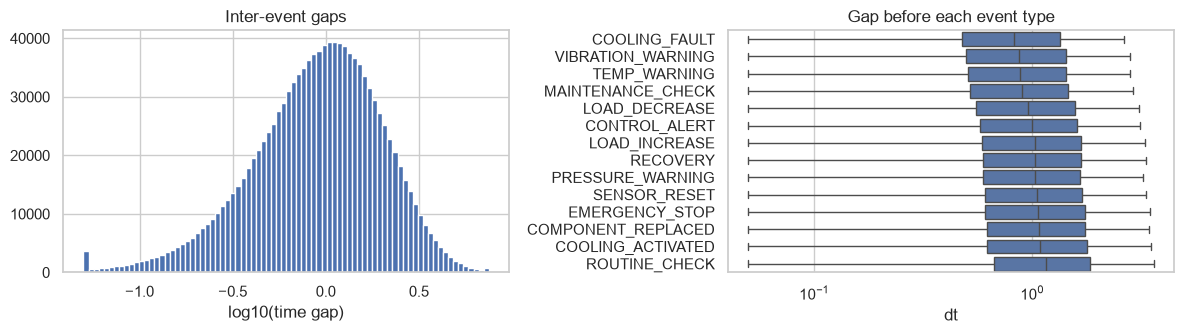

In [14]:
dt = train["dt"].dropna()
display(dt.describe(percentiles=[.01, .1, .25, .5, .75, .9, .99]).to_frame("time gap").T)
print(f"coefficient of variation (std/mean): {dt.std() / dt.mean():.2f}  (exponential gaps, i.e. a Poisson process, would give 1.0)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(np.log10(dt[dt > 0]), bins=80)
axes[0].set_xlabel("log10(time gap)"); axes[0].set_title("Inter-event gaps")
# Gap that PRECEDES each event type (relevant for generating time gaps later)
gap_before = train.dropna(subset=["dt"])
order = gap_before.groupby("event_type")["dt"].median().sort_values().index
sns.boxplot(data=gap_before, x="dt", y="event_type", order=order, ax=axes[1], showfliers=False)
axes[1].set_xscale("log"); axes[1].set_title("Gap before each event type"); axes[1].set_ylabel("")
plt.tight_layout(); savefig("time_gaps"); plt.show()

,MI with next event (nats)
last gap (dt),0.0116
time for last 5 events,0.0353
time for last 20 events,0.0497
current event (reference),0.4030


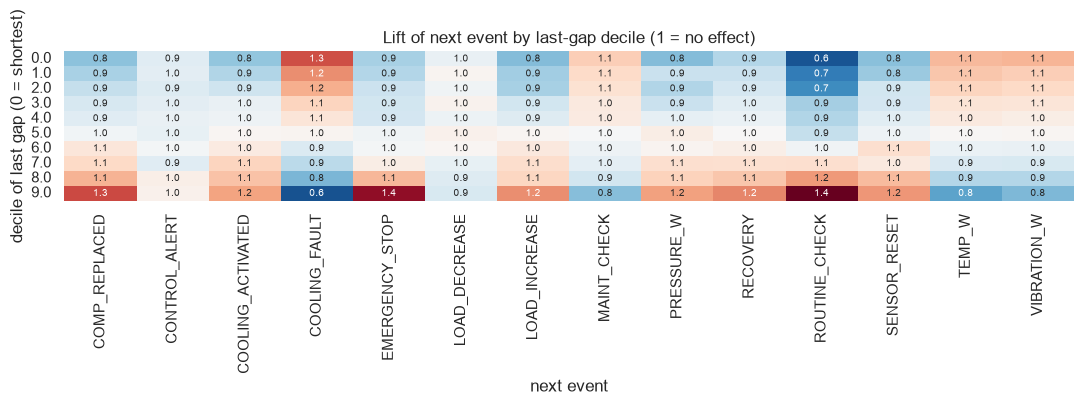

In [15]:
# Timing features known at prediction time
gs = train.groupby("sequence_id", sort=False)["timestamp"]
for n in [5, 20]:
    train[f"span_last{n}"] = train["timestamp"] - gs.shift(n)          # time taken by the last n events
sup[["span_last5", "span_last20"]] = train.loc[sup.index, ["span_last5", "span_last20"]]
sup["dt_prev"] = train["dt"].loc[sup.index]

time_mi = pd.Series({
    "last gap (dt)": mutual_info(qbin(sup["dt_prev"])),
    "time for last 5 events": mutual_info(qbin(sup["span_last5"])),
    "time for last 20 events": mutual_info(qbin(sup["span_last20"])),
    "current event (reference)": mutual_info(sup["ev"]),
}).round(4)
display(time_mi.to_frame("MI with next event (nats)"))

# Next-event distribution by last-gap decile, relative to the overall prior (lift)
next_name = sup["y"].map(dict(enumerate(CLASSES)))
lift = pd.crosstab(qbin(sup["dt_prev"]), next_name, normalize="index") / next_name.value_counts(normalize=True)
plt.figure(figsize=(11, 4))
sns.heatmap(lift.rename(columns=SHORT), cmap="RdBu_r", center=1, annot=True, fmt=".1f", annot_kws={"size": 7}, cbar=False)
plt.yticks(rotation=0)
plt.ylabel("decile of last gap (0 = shortest)"); plt.xlabel("next event"); plt.title("Lift of next event by last-gap decile (1 = no effect)")
plt.tight_layout(); savefig("gap_lift"); plt.show()

In [16]:
# The span features are NaN for the first 5/20 events of every sequence, so their NaN bin partly encodes
# "we are in the warm-up phase" (Section 3). Re-check on test-like rows, and conditional on the current event.
rows = sup.loc[TL]
timing_check = pd.DataFrame({
    name: {
        "MI (all rows, above)": mutual_info(qbin(sup[col])),
        "NaN share (all rows)": sup[col].isna().mean(),
        "MI (test-like rows)": mutual_info(qbin(rows[col]), rows["y"]),
        "MI | current event (test-like rows)": cond_mi_on(qbin(rows[col]), rows),
    }
    for name, col in [("last gap (dt)", "dt_prev"), ("time for last 5 events", "span_last5"),
                      ("time for last 20 events", "span_last20")]
}).T
display(timing_check.round(4))

,"MI (all rows, above)",NaN share (all rows),MI (test-like rows),MI | current event (test-like rows)
last gap (dt),0.0116,0.0054,0.0073,0.0054
time for last 5 events,0.0353,0.0271,0.0211,0.0116
time for last 20 events,0.0497,0.1086,0.0242,0.0124


> **Notes**
>
> - **Gap shape:** roughly log-normal (median 0.96), bounded to [0.05, 7.5], and more regular than random arrivals (std/mean 0.76 vs. 1.0 for exponential gaps), so we model log(gap).
> - **Signal:** modest. On test-like rows, the time taken by the last 5–20 events adds about 0.012 nats beyond the current event. The raw estimate of 0.050 was mostly a warm-up artefact (the span features are NaN in the first 5/20 events).
> - **Which events:** after short gaps COOLING_FAULT is more likely (lift 1.3); after long gaps ROUTINE_CHECK, EMERGENCY_STOP and RECOVERY are (lift 1.2–1.4).
> - **Decision:** include timing features as a secondary group and test them with an ablation.

## 6. Context columns
Which context columns describe the **system** (constant within a sequence) and which change per
event? Are any redundant with `event_type`?

In [17]:
ctx = ["subsystem", "severity", "shift_code", "operator_group", "device_family", "firmware_channel"]
g = train.groupby("sequence_id")
summary = pd.DataFrame({
    "n values": [train[c].nunique() for c in ctx],
    "constant within sequence (frac of seqs)": [(g[c].nunique() == 1).mean() for c in ctx],
    "MI with current event_type": [mutual_info(train.loc[sup.index, c], sup["ev"]) for c in ctx],
    "MI with next event": [mutual_info(sup[c]) for c in ctx],
}, index=ctx).round(4)
display(summary)

,n values,constant within sequence (frac of seqs),MI with current event_type,MI with next event
subsystem,6,0.0,1.2710,0.2178
severity,4,0.0,0.5422,0.1305
shift_code,3,0.0,0.0007,0.0005
operator_group,5,0.0,0.0000,0.0000
device_family,4,1.0,0.0010,0.0010
firmware_channel,4,1.0,0.0001,0.0001


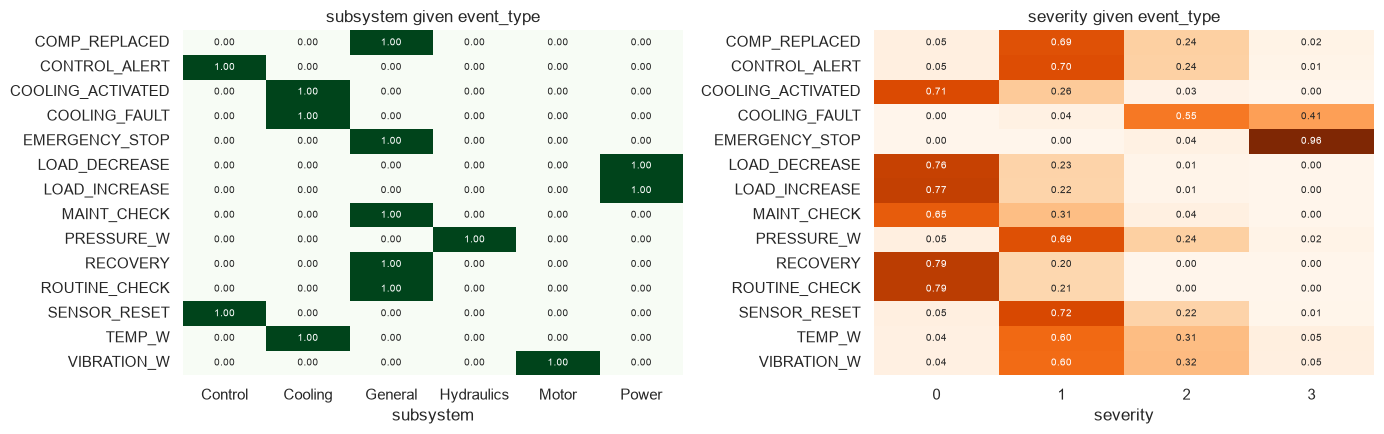

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ct = pd.crosstab(train["event_type"].map(SHORT), train["subsystem"], normalize="index")
sns.heatmap(ct, annot=True, fmt=".2f", cmap="Greens", cbar=False, ax=axes[0], annot_kws={"size": 7})
axes[0].set_title("subsystem given event_type"); axes[0].set_ylabel("")
ct = pd.crosstab(train["event_type"].map(SHORT), train["severity"], normalize="index")
sns.heatmap(ct, annot=True, fmt=".2f", cmap="Oranges", cbar=False, ax=axes[1], annot_kws={"size": 7})
axes[1].set_title("severity given event_type"); axes[1].set_ylabel("")
plt.tight_layout(); savefig("context_vs_event"); plt.show()

In [19]:
# Does context add information BEYOND the current event? Conditional MI: I(context; next | current event)
def cond_mi(x, cond):
    tot = 0.0
    for c, idx in sup.groupby(cond).groups.items():
        w = len(idx) / len(sup)
        tot += w * mutual_info(np.asarray(x.loc[idx]), sup.loc[idx, "y"])
    return tot

cmi = pd.Series({c: cond_mi(sup[c], sup["ev"]) for c in ctx}).round(4)
display(cmi.to_frame("I(context; next | current event) (nats)"))

,I(context; next | current event) (nats)
subsystem,0.0000
severity,0.0050
shift_code,0.0007
operator_group,0.0003
device_family,0.0008
firmware_channel,0.0003


> **Notes**
>
> - **System vs. event level:** `device_family` and `firmware_channel` are constant within each sequence (system-level); `subsystem`, `severity`, `shift_code` and `operator_group` change per event.
> - **`subsystem` is redundant:** it is a deterministic grouping of the 14 event types into 6 families, so it adds exactly nothing once the current event is known.
> - **`severity`:** follows the expected ranking (routine 0 → warning 1 → fault 2–3 → emergency stop 3) and still adds a little within an event type (conditional MI 0.005).
> - **No signal:** `shift_code`, `operator_group`, `device_family` and `firmware_channel` add at most 0.0008 nats beyond the current event, which is negligible. Section 8 confirms that the system-level columns explain little.
> - **Decision:** drop `subsystem` as a direct feature (it may still group history counts); keep `severity` as an ordinal feature; drop `shift_code`, `operator_group` and `firmware_channel`; `device_family` is low priority (checked by ablation).

## 7. Sensors
The brief warns that measurements may be **noisy, missing, redundant, or temporarily unreliable**.
We check each of these.

**7a. Missingness.** How much is missing, does it co-occur, and does it depend on event type?

,load_reading,temperature_reading,temp_probe_b,vibration_reading,vibration_probe_b,pressure_reading,power_draw,coolant_flow,control_signal,ambient_index,efficiency_estimate,acoustic_level,telemetry_ch_1,telemetry_ch_3,telemetry_ch_4,telemetry_ch_2
missing frac,0.0156,0.0154,0.0156,0.0156,0.0157,0.0154,0.0155,0.0156,0.0155,0.0,0.0126,0.0127,0.0124,0.0126,0.0126,0.0126


Rows by number of missing sensors:


,0,1,2,3,4,5
frac of rows,0.8048,0.176,0.018,0.0011,0.0,0.0


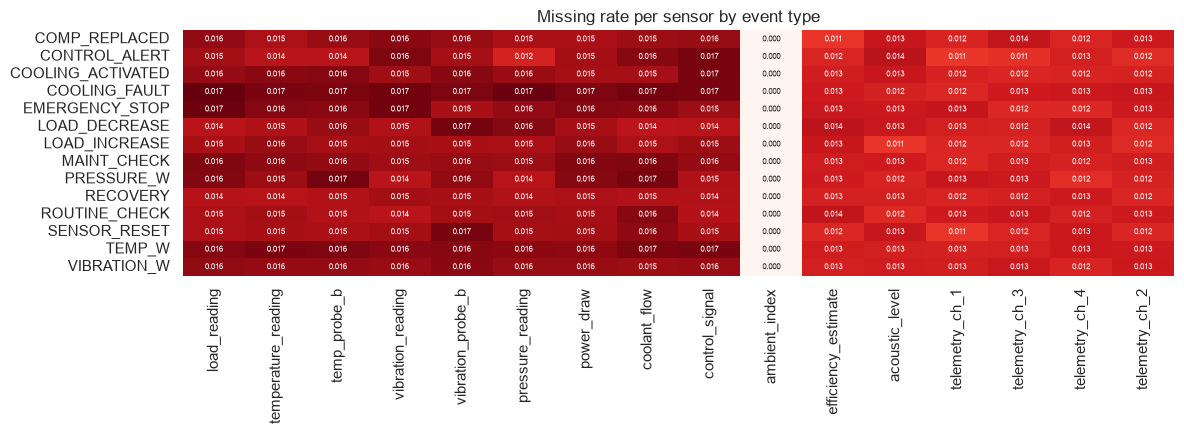

MI(any sensor missing; next) = 0.0001 nats


In [20]:
miss = train[SENSORS].isna()
n_miss_row = miss.sum(axis=1)
display(pd.DataFrame({"missing frac": miss.mean()}).T.round(4))
print("Rows by number of missing sensors:")
display(n_miss_row.value_counts(normalize=True).sort_index().round(4).to_frame("frac of rows").T)

miss_by_event = miss.groupby(train["event_type"].map(SHORT)).mean()
plt.figure(figsize=(12, 4.5))
sns.heatmap(miss_by_event, annot=True, fmt=".3f", cmap="Reds", cbar=False, annot_kws={"size": 6})
plt.title("Missing rate per sensor by event type"); plt.ylabel("")
plt.tight_layout(); savefig("missing_by_event"); plt.show()

print(f"MI(any sensor missing; next) = {mutual_info((n_miss_row.loc[sup.index] > 0).astype(int)):.4f} nats")

**7b. Distributions and outliers.**

,count,mean,std,min,1%,50%,99%,max
load_reading,1185131.0,0.537,0.220,-3.238,0.053,0.538,1.038,4.149
temperature_reading,1185372.0,0.436,0.209,-3.283,0.019,0.419,0.986,4.529
temp_probe_b,1185188.0,0.436,0.227,-2.973,-0.036,0.423,1.016,4.349
vibration_reading,1185139.0,0.500,0.288,-3.371,0.002,0.453,1.305,4.795
vibration_probe_b,1185102.0,0.499,0.293,-3.270,-0.024,0.456,1.309,3.973
pressure_reading,1185445.0,0.461,0.165,-3.276,0.106,0.457,0.854,4.190
power_draw,1185244.0,0.429,0.191,-2.462,0.008,0.427,0.872,3.970
coolant_flow,1185184.0,0.349,0.267,-3.195,-0.193,0.434,0.751,3.898
control_signal,1185266.0,0.970,0.162,-2.986,0.516,0.988,1.277,4.414
ambient_index,1203963.0,0.000,0.252,-1.103,-0.575,0.000,0.575,1.106


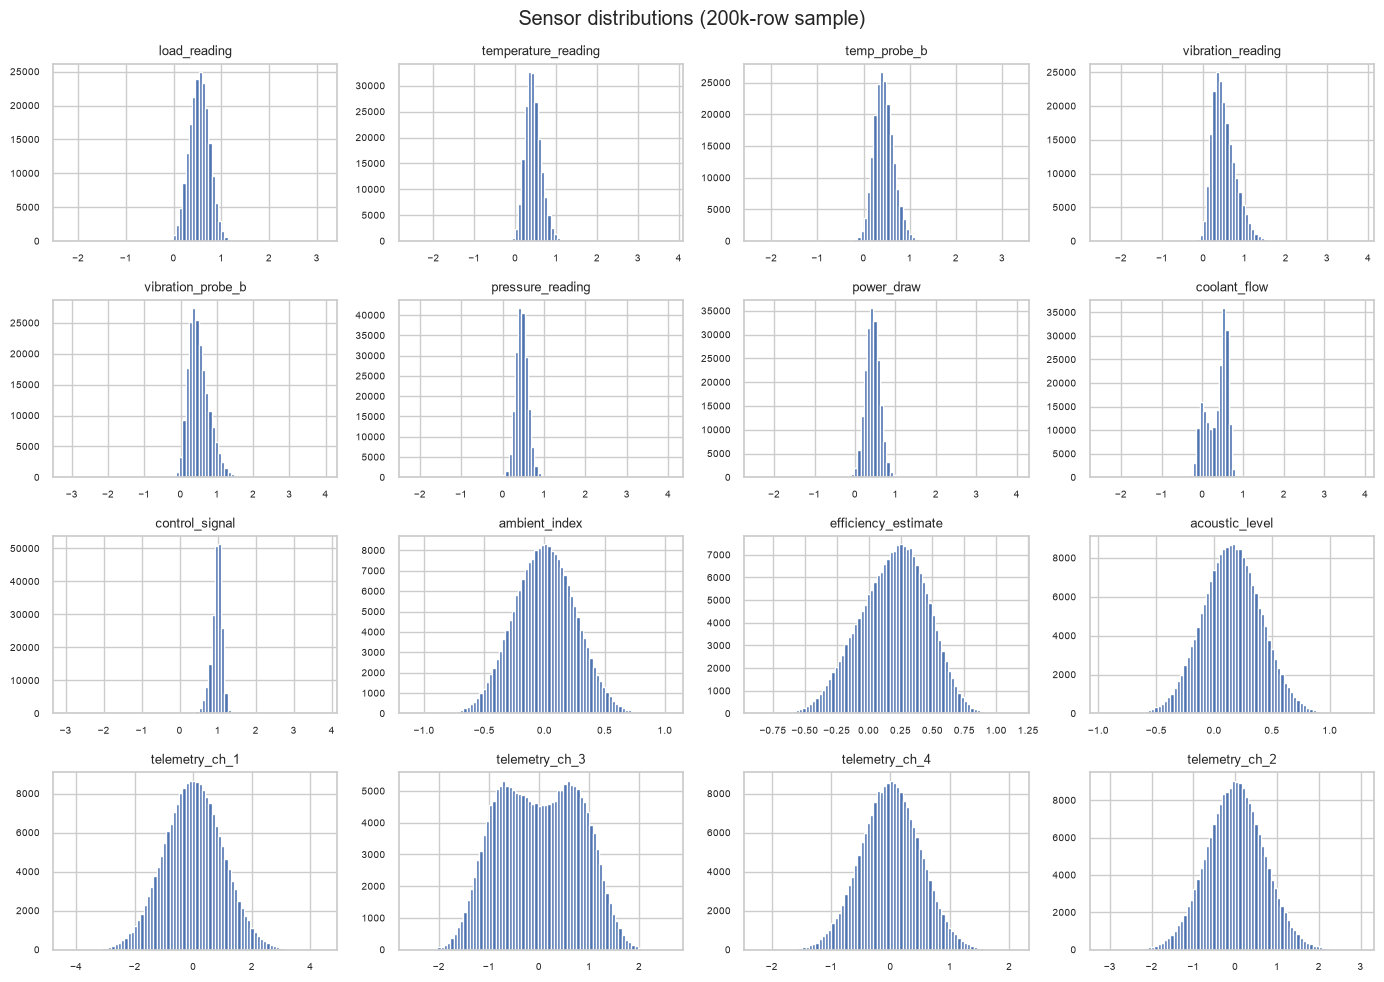

,load_reading,temperature_reading,temp_probe_b,vibration_reading,vibration_probe_b,pressure_reading,power_draw,coolant_flow,control_signal,ambient_index,efficiency_estimate,acoustic_level,telemetry_ch_1,telemetry_ch_3,telemetry_ch_4,telemetry_ch_2
frac |robust z| > 5,0.0007,0.0009,0.0007,0.0003,0.0002,0.0019,0.0011,0.0001,0.0026,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [21]:
display(train[SENSORS].describe(percentiles=[.01, .5, .99]).T.round(3))

sample = train[SENSORS].sample(200_000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(4, 4, figsize=(14, 10))
for ax, c in zip(axes.ravel(), SENSORS):
    ax.hist(sample[c].dropna(), bins=80)
    ax.set_title(c, fontsize=9); ax.tick_params(labelsize=7)
plt.suptitle("Sensor distributions (200k-row sample)"); plt.tight_layout(); savefig("sensor_hists"); plt.show()

med = train[SENSORS].median(); iqr = train[SENSORS].quantile(.75) - train[SENSORS].quantile(.25)
robust_z = ((train[SENSORS] - med) / iqr).abs()
display((robust_z > 5).mean().round(4).to_frame("frac |robust z| > 5").T)

**7c. Redundancy.** Correlations between sensors (Spearman, on the sample).

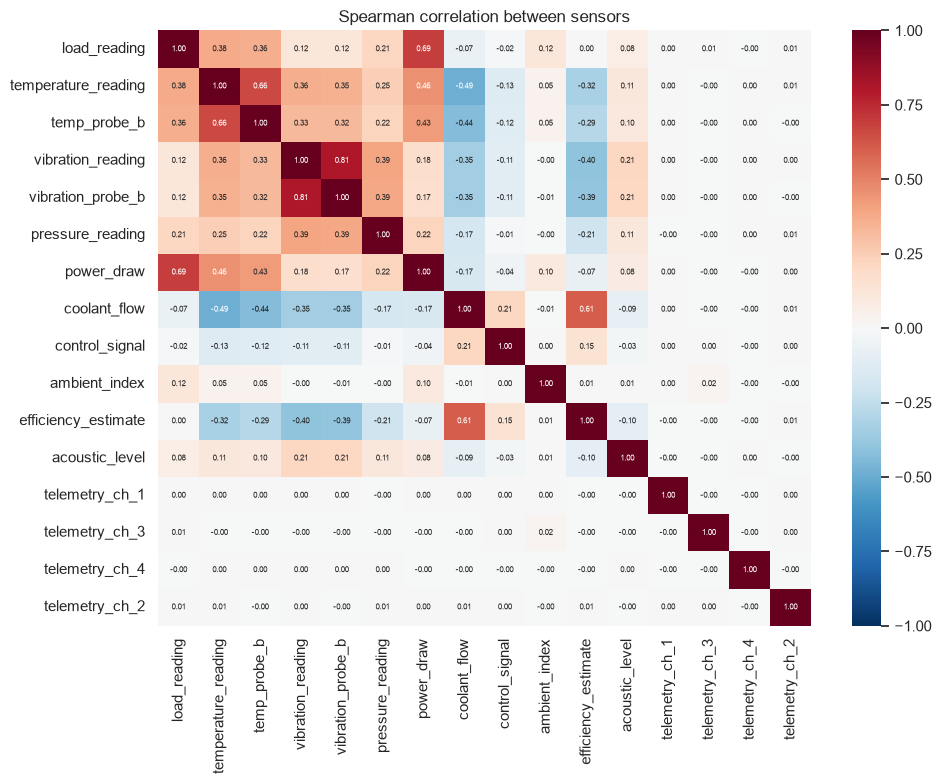

spearman
vibration_reading   vibration_probe_b       0.810
load_reading        power_draw              0.688
temperature_reading temp_probe_b            0.664
coolant_flow        efficiency_estimate     0.607
temperature_reading coolant_flow           -0.486
                    power_draw              0.460
temp_probe_b        coolant_flow           -0.437
                    power_draw              0.427
vibration_reading   efficiency_estimate    -0.403
vibration_probe_b   efficiency_estimate    -0.392

In [22]:
corr = sample.corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 6})
plt.title("Spearman correlation between sensors"); plt.tight_layout(); savefig("sensor_corr"); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
display(pairs.head(10).round(3).to_frame("spearman"))

**7d. Temporarily unreliable?** Stuck values (same reading as the previous event), and how the
disagreement between duplicate probes behaves after a `SENSOR_RESET`.

,load_reading,temperature_reading,temp_probe_b,vibration_reading,vibration_probe_b,pressure_reading,power_draw,coolant_flow,control_signal,ambient_index,efficiency_estimate,acoustic_level,telemetry_ch_1,telemetry_ch_3,telemetry_ch_4,telemetry_ch_2
frac equal to previous reading,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,|temp - temp_probe_b|,|vib - vibration_probe_b|,any sensor missing
events since last SENSOR_RESET,,,
0.0,0.1318,0.1261,0.1931
1.0,0.1313,0.1254,0.1952
2.0,0.1303,0.1259,0.1951
3.0,0.1322,0.1263,0.1943
4.0,0.1339,0.1280,0.1936
5.0,0.1317,0.1277,0.1918
6.0,0.1357,0.1276,0.1965
7.0,0.1339,0.1264,0.1894
30.0,0.1338,0.1256,0.1960


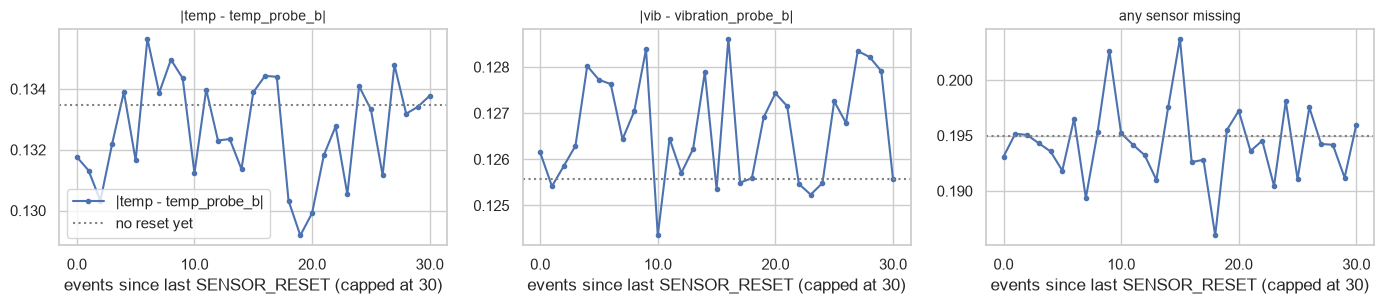

In [23]:
prev = train.groupby("sequence_id", sort=False)[SENSORS].shift(1)
stuck = (train[SENSORS] == prev).mean()
display(stuck.round(4).to_frame("frac equal to previous reading").T)

# Events since the last SENSOR_RESET within the sequence
is_reset = train["event_type"].eq("SENSOR_RESET")
last_reset = train["pos"].where(is_reset).groupby(train["sequence_id"], sort=False).ffill()
since_reset = (train["pos"] - last_reset).clip(upper=30)       # NaN = no reset yet

probe = pd.DataFrame({
    "|temp - temp_probe_b|": (train["temperature_reading"] - train["temp_probe_b"]).abs(),
    "|vib - vibration_probe_b|": (train["vibration_reading"] - train["vibration_probe_b"]).abs(),
    "any sensor missing": (n_miss_row > 0).astype(float),
})
by_since = probe.groupby(since_reset.rename("events since last SENSOR_RESET")).mean()
by_since.loc["no reset yet"] = probe[since_reset.isna()].mean()
display(by_since.iloc[list(range(0, 8)) + [-2, -1]].round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, c in zip(axes, probe.columns):
    by_since[c].iloc[:-1].plot(ax=ax, marker=".")
    ax.axhline(by_since[c].iloc[-1], ls=":", c="grey", label="no reset yet"); ax.set_title(c, fontsize=10)
    ax.set_xlabel("events since last SENSOR_RESET (capped at 30)")
axes[0].legend(); plt.tight_layout(); savefig("since_reset"); plt.show()

Do problems come in **episodes**? If unreliability is temporary, a bad reading should make the next
reading more likely to be bad too: disagreement between duplicate probes should be autocorrelated,
and outliers should cluster. Missingness is checked the same way for comparison.

In [24]:
def within_seq_autocorr(s, lag):
    return s.corr(s.groupby(train["sequence_id"], sort=False).shift(lag))

episodes = pd.DataFrame({
    name: {f"autocorr lag {l}": within_seq_autocorr(s, l) for l in [1, 2, 5, 10]}
    for name, s in [("|temp - temp_probe_b|", probe.iloc[:, 0]), ("|vib - vibration_probe_b|", probe.iloc[:, 1])]
}).T
display(episodes.round(3))

def clustering(flag, label):
    prev_flag = flag.groupby(train["sequence_id"], sort=False).shift(1)
    return pd.Series({"P(flag)": flag.mean(), "P(flag | previous event flagged)": flag[prev_flag == True].mean()}, name=label)

outlier_row = (robust_z > 5).any(axis=1)
display(pd.concat([clustering(outlier_row, "any sensor |robust z| > 5"),
                   clustering(n_miss_row > 0, "any sensor missing")], axis=1).T.round(4))

,autocorr lag 1,autocorr lag 2,autocorr lag 5,autocorr lag 10
|temp - temp_probe_b|,0.245,0.171,0.086,0.031
|vib - vibration_probe_b|,0.236,0.170,0.075,0.018


,P(flag),P(flag | previous event flagged)
any sensor |robust z| > 5,0.0084,0.0653
any sensor missing,0.1952,0.1950


**7e. Do sensors inform the next event?** MI of the current reading (deciles), of its change since
the previous event, and conditional on the current event (does it add anything beyond `event_type`?).
Rough noise floor for these in-sample estimates: about 0.001 nats. Values near that mean "no signal".

,value,change vs prev,value | current event
coolant_flow,0.0935,0.0025,0.0295
vibration_reading,0.0932,0.0042,0.0280
vibration_probe_b,0.0871,0.0039,0.0260
temperature_reading,0.0614,0.0051,0.0156
efficiency_estimate,0.0540,0.0014,0.0172
temp_probe_b,0.0523,0.0026,0.0132
control_signal,0.0190,0.0011,0.0057
power_draw,0.0152,0.0021,0.0073
load_reading,0.0116,0.0034,0.0080
pressure_reading,0.0107,0.0012,0.0059


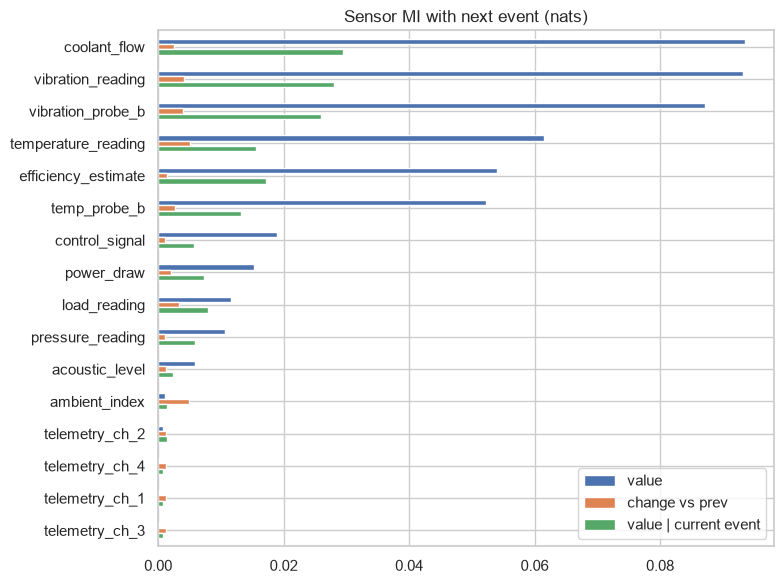

In [25]:
prev_sup = prev.loc[sup.index]
sens_mi = pd.DataFrame({
    "value": {c: mutual_info(qbin(sup[c])) for c in SENSORS},
    "change vs prev": {c: mutual_info(qbin(sup[c] - prev_sup[c])) for c in SENSORS},
    "value | current event": {c: cond_mi(qbin(sup[c]), sup["ev"]) for c in SENSORS},
}).sort_values("value", ascending=False)
display(sens_mi.round(4))
sens_mi.plot.barh(figsize=(8, 6), title="Sensor MI with next event (nats)")
plt.gca().invert_yaxis(); plt.tight_layout(); savefig("sensor_mi"); plt.show()

> **Notes**
>
> - **Missing values:** 1.2–1.6% per sensor (`ambient_index` is never missing) and completely at random: unrelated to event type, uninformative about the next event (MI 0.0001), and not clustered in time (a missing reading doesn't make the next one more likely to be missing).
> - **Spikes:** |robust z| > 5 in 0.84% of rows, only in the 9 physical sensors, and in short episodes (about 8× more likely right after a spike).
> - **Probe disagreement:** also comes in episodes (lag-1 autocorrelation 0.24). Together with the spikes, this is the "temporarily unreliable" behaviour from the brief.
> - **What we didn't find:** no stuck readings, and `SENSOR_RESET` changes neither probe disagreement nor missingness.
> - **Redundancy:** the duplicate probes are strongly correlated (ρ = 0.66 for temperature, 0.81 for vibration).
> - **Signal:** cooling, vibration and temperature sensors add up to ~0.03 nats beyond the current event, more than timing or severity. `telemetry_ch_1–4`, `ambient_index` and `acoustic_level` are indistinguishable from noise. Levels matter more than changes since the previous event.
> - **Decision:** simple median imputation and no missing flags; clip extreme values and prefer rolling medians to single readings; average the duplicate probes; drop the noise channels (confirmed by ablation).

## 8. Differences between systems
The brief says different systems have different operating characteristics. If systems differ a lot
in their baseline sensor levels, **per-sequence normalisation** (e.g. value minus the sequence's
running mean) may help. If event habits differ, sequence-level summaries become useful features.

,coolant_flow,temperature_reading,temp_probe_b,vibration_reading,vibration_probe_b,load_reading,pressure_reading,efficiency_estimate,power_draw,telemetry_ch_2,control_signal,telemetry_ch_4,acoustic_level,ambient_index,telemetry_ch_1,telemetry_ch_3
between-system share of variance,0.481,0.397,0.359,0.318,0.316,0.297,0.263,0.261,0.23,0.221,0.202,0.07,0.031,0.017,0.006,0.005


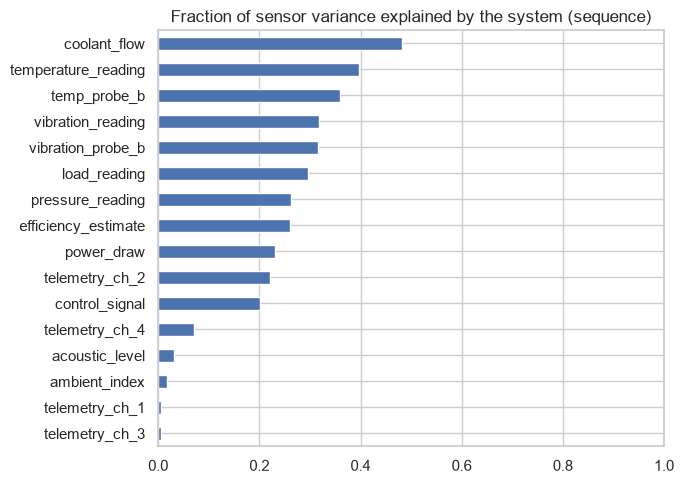

In [26]:
# Share of each sensor's variance that is BETWEEN sequences (vs. within a sequence)
seq_mean = train.groupby("sequence_id")[SENSORS].transform("mean")
between = (seq_mean.var() / train[SENSORS].var()).sort_values(ascending=False)
display(between.round(3).to_frame("between-system share of variance").T)
between.plot.barh(figsize=(7, 5), title="Fraction of sensor variance explained by the system (sequence)")
plt.gca().invert_yaxis(); plt.xlim(0, 1); plt.tight_layout(); savefig("between_seq_variance"); plt.show()

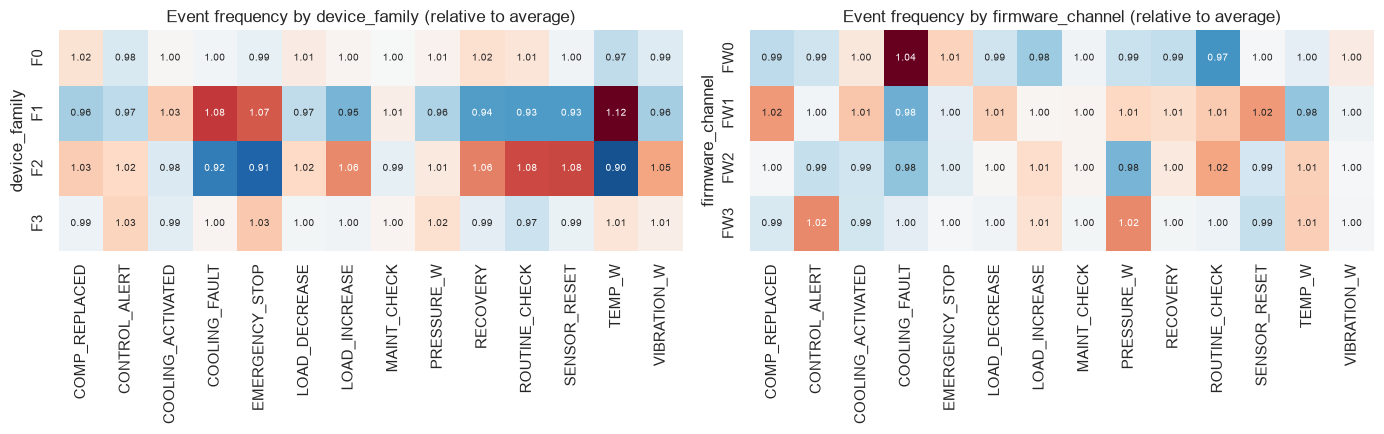

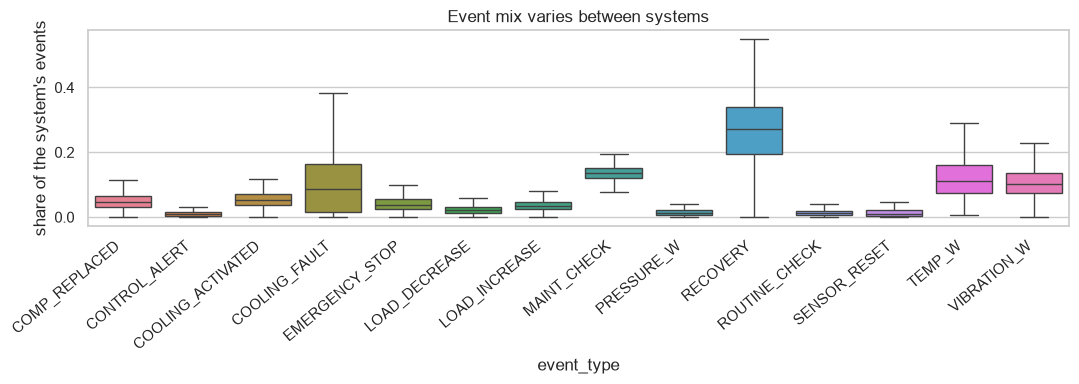

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, c in zip(axes, ["device_family", "firmware_channel"]):
    ct = pd.crosstab(train[c], train["event_type"].map(SHORT), normalize="index")
    sns.heatmap(ct / ct.mean(), cmap="RdBu_r", center=1, annot=True, fmt=".2f", cbar=False, ax=ax, annot_kws={"size": 7})
    ax.set_title(f"Event frequency by {c} (relative to average)"); ax.set_xlabel("")
plt.tight_layout(); savefig("events_by_system_group"); plt.show()

# How different are individual systems? Per-sequence event frequencies
per_seq = pd.crosstab(train["sequence_id"], train["event_type"].map(SHORT), normalize="index")
plt.figure(figsize=(11, 4))
sns.boxplot(data=per_seq, showfliers=False)
plt.xticks(rotation=40, ha="right"); plt.ylabel("share of the system's events")
plt.title("Event mix varies between systems"); plt.tight_layout(); savefig("per_seq_event_mix"); plt.show()

**Follow-up checks on test-like rows** (using only information available at prediction time).
1. Does **per-system normalisation** (value minus the system's running mean so far) carry more information than the raw value?
2. The system's event habits: the **share of each event so far** (past only), compared with the share over the whole
   sequence, which peeks into the future and is therefore optimistic.

In [28]:
rows = sup.loc[TL]
seq = train["sequence_id"]

# (1) Per-system normalisation: raw value vs. deviation from the system's running mean (past + current only)
norm = {}
for c in ["coolant_flow", "vibration_reading", "temperature_reading", "efficiency_estimate",
          "load_reading", "power_draw", "control_signal", "pressure_reading"]:
    x = train[c]
    run_mean = (x.fillna(0).groupby(seq, sort=False).cumsum()
                / x.notna().astype(int).groupby(seq, sort=False).cumsum().replace(0, np.nan))
    norm[c] = {
        "raw value": cond_mi_on(qbin(rows[c]), rows),
        "deviation from running mean": cond_mi_on(qbin((x - run_mean).loc[TL]), rows),
        "running mean alone": cond_mi_on(qbin(run_mean.loc[TL]), rows),
    }
display(pd.DataFrame(norm).T.round(4).rename_axis("I(.; next | current event), test-like rows"))

# (2) System habits: share of each event so far (past only) vs. whole-sequence share (uses the future)
top = per_seq.columns[per_seq.std().argsort()[::-1][:5]]       # the 5 events whose share varies most between systems
seq_share = per_seq.loc[sup["sequence_id"], top].set_index(sup.index)
FULL_NAME = {short: full for full, short in SHORT.items()}
share_cmi = {}
for c in top:
    code_c = CLASSES.index(FULL_NAME[c])
    so_far = (train["ev"] == code_c).astype(int).groupby(seq, sort=False).cumsum() / (train["pos"] + 1)
    share_cmi[c] = {
        "whole-sequence share (uses the future)": cond_mi_on(qbin(seq_share.loc[TL, c], 5), rows),
        "share so far (past only)": cond_mi_on(qbin(so_far.loc[TL], 5), rows),
    }
display(pd.DataFrame(share_cmi).T.round(4).rename_axis("I(.; next | current event), test-like rows"))

,raw value,deviation from running mean,running mean alone
"I(.; next | current event), test-like rows",,,
coolant_flow,0.0287,0.0209,0.0113
vibration_reading,0.0317,0.0312,0.0070
temperature_reading,0.0176,0.0119,0.0088
efficiency_estimate,0.0179,0.0114,0.0108
load_reading,0.0086,0.0090,0.0043
power_draw,0.0081,0.0065,0.0057
control_signal,0.0041,0.0027,0.0030
pressure_reading,0.0058,0.0044,0.0038


,whole-sequence share (uses the future),share so far (past only)
"I(.; next | current event), test-like rows",,
RECOVERY,0.0206,0.0160
COOLING_FAULT,0.0244,0.0156
TEMP_W,0.0182,0.0128
VIBRATION_W,0.0119,0.0064
COMP_REPLACED,0.0114,0.0098


> **Notes**
>
> - **Systems differ strongly:** 32–48% of the variance of the key sensors (coolant, temperature, vibration) is between systems, and the per-system event mix varies widely (box-plot whiskers: RECOVERY 0–55%, COOLING_FAULT 0–38%).
> - **The labelled system type explains little:** `device_family` shifts event frequencies by about ±10% and `firmware_channel` has no visible effect, so each system's character has to be inferred from its own history.
> - **Per-system normalisation loses information:** on test-like rows, the deviation from the system's running mean never carries clearly more information than the raw reading (coolant 0.029 → 0.021, temperature 0.018 → 0.012, efficiency 0.018 → 0.011; load and vibration roughly equal), because a system's typical level is itself informative (running mean alone: 0.003–0.011).
> - **System habits survive without the future:** the past-only event share so far adds 0.006–0.016 nats beyond the current event, about 30% less on average (14–46% per event) than the whole-sequence share, which was optimistic because it includes the target and later events. This is consistent with the small constant long-range dependence in Section 4c. Test prefixes have at least 90 events, so the share so far is well estimated.
> - **Decision:** keep raw sensor levels (clipped and robust-scaled) and add running means as separate system descriptors; add the event share so far for the events whose share varies most between systems (RECOVERY, COOLING_FAULT, TEMP_W, VIBRATION_W, COMP_REPLACED). Strong system habits are another reason to group validation by sequence.

## 9. Summary: findings → decisions

| # | Finding | Evidence | Implication for our pipeline |
|---|---------|----------|------------------------------|
| 1 | Data is internally consistent; test sequences are unseen systems (0 overlap with train). | §1 sanity table | No cleaning needed. Validation must be **grouped by `sequence_id`**. IDs are used only for grouping and deriving features. |
| 2 | Test prefixes are full sequences minus their last 30 events (KS p = 0.78 at offset 30). The end of a sequence is not special, but the first ~50 events are a warm-up phase with a different event mix. | §3: KS / KL / χ² checks, `eda_mix_by_position` | Training targets are cut at prefix lengths **90–220** (test-like; 596,953 examples). Earlier events are kept as **history**, just not used as targets. |
| 3 | History is the main signal: held-out n-gram log loss 2.24 → 1.83 (1 event) → 1.70 (3 events), then gets worse as contexts become sparse. Single-lag dependence reaches ~30 events, then stays at a small system-level floor. | §4a `eda_ngram_logloss`, §4c `eda_lag_mi` | Models must generalise over a **context of ~30–50 events**: engineered history features for the classical model, sequence models (RNN / Transformer) for the deep ones. |
| 4 | Counts of events in the last 30 add up to 0.043 nats beyond the current event (TEMP_W, RECOVERY, COOLING_FAULT), more than the best sensor (0.030). | §4d: count MI given the current event | **Window counts are a core feature group.** Confirm with a feature-group ablation. |
| 5 | Systems have their own habits: 32–48% of key sensor variance is between systems; the past-only event share so far adds 0.006–0.016 nats. The labelled system type (`device_family`, `firmware_channel`) explains little. | §8 `eda_between_seq_variance`, `eda_per_seq_event_mix`, follow-up checks | Infer each system's character from its **own history** (event share so far, sensor running means). Another reason to group validation by sequence. |
| 6 | Timing is a modest, secondary signal: on test-like rows the time taken by the last 20 events adds 0.012 nats beyond the current event (the raw 0.050 was inflated by the warm-up phase). Gaps are roughly log-normal. | §5 `timing_check`, `eda_time_gaps`, `eda_gap_lift` | Include log(gap) and span-of-last-n features, test them with an ablation, and generate time gaps in log space. |
| 7 | Sensors: coolant, vibration and temperature add up to ~0.03 nats beyond the current event; levels matter more than changes. `telemetry_ch_1–4`, `ambient_index` and `acoustic_level` are at the noise floor. Duplicate probes are redundant (ρ = 0.66–0.81). | §7c `eda_sensor_corr`, §7e `eda_sensor_mi` | Keep the physical sensors, **average duplicate probes**, drop noise channels (confirm by ablation). |
| 8 | Sensor problems are mild: ~1.2–1.6% missing per sensor, completely at random; spikes in 0.84% of rows that come in short episodes (8× more likely after a spike), as does probe disagreement. | §7a `eda_missing_by_event`, §7d episode checks | Simple median imputation (fitted on training folds only), no missing flags; clip extreme values; prefer **rolling medians** over single readings. |
| 9 | Per-system normalisation loses information: the deviation from a system's running mean never beats the raw value (coolant 0.029 → 0.021). | §8 follow-up checks | Keep raw levels (clipped and robust-scaled); add running means as **separate** system descriptors. |
| 10 | Context columns: `subsystem` is a deterministic grouping of `event_type` (0 extra information); `severity` adds a little (0.005); `shift_code`, `operator_group` and `firmware_channel` carry no signal. | §6 tables, `eda_context_vs_event` | Drop `subsystem`, `shift_code`, `operator_group` and `firmware_channel` as direct features; keep `severity` as ordinal; `device_family` is low priority. |
| 11 | Classes are imbalanced (28.5×, RECOVERY 26.7% vs CONTROL_ALERT 0.9%); predicting the prior scores 2.239. | §2 `eda_class_freq` | No re-weighting or oversampling (it would hurt calibration). Never predict near-zero probabilities. Any model worse than 2.239 is broken. |

**Implications for step 2 (sample construction + validation):**
- Build one example per (sequence, cut point) with prefix length 90–220, so the target is event 90…220. All events before the cut are available as history.
- Examples from the same sequence are highly correlated, so folds are made with **GroupKFold on `sequence_id`** (fixed seed 2210), and every model uses the same folds.
- Longer sequences produce more cut points, while the test set has exactly one prefix per system. Consider weighting each validation sequence equally, or evaluating on a fixed random cut per sequence, so the validation log loss mirrors the test set.
- Everything learned from data (clipping thresholds, scalers, imputers, vocabularies) is fitted on the training folds only. Features only use events up to and including the current one.

**Feature ideas to test in phase 2:**
- **Recent events:** last 1–3 event types and their severities; run length of the current event (strong self-transitions: RECOVERY 0.73, COOLING_FAULT 0.57).
- **Window counts:** count of each event type in the last 5 / 10 / 30 events; events (and time) since the last occurrence of each type.
- **System habits:** share of each event so far (at least for RECOVERY, COOLING_FAULT, TEMP_W, VIBRATION_W, COMP_REPLACED); running means of the key sensors.
- **Timing:** log(last gap), log(time taken by the last 5 / 20 events).
- **Sensors:** averaged duplicate probes, clipped and robust-scaled levels, rolling medians over the last 3–5 events.
- **Deprioritised or dropped** (to confirm by ablation): `subsystem`, `shift_code`, `operator_group`, `firmware_channel`, `telemetry_ch_1–4`, `ambient_index`, `acoustic_level`, missing-value flags, per-system normalisation.